# Quick start on synthetic EEG

> **Research prototype, not a medical device.** Scores are research outputs, not diagnoses.

This notebook runs end to end without the confidential dataset:

1. generate synthetic recordings of a 6-channel consumer EEG headband (EDF) with a minimal EDF writer;
2. look at one trace and its occipital spectrum;
3. compute the four Set A features;
4. verify and load the shipped C2G weights (plain `.npz`, no pickle);
5. score every synthetic subject, including edge cases that must fall back to the prior;
6. inspect the ensemble coefficients.

The synthetic signals are pink noise plus band-limited alpha/beta components. They exercise the code path; they say nothing about PTSD.

In [1]:
import sys, warnings
from pathlib import Path

REPO = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
for p in (REPO / "src", REPO / "examples"):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))
warnings.simplefilter("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.precision", 4)
pd.set_option("display.width", 140)

## 1. Synthetic recordings

`make_demo_set` writes one folder per subject with a rest file `rest.edf` and five task files (`task1.edf` … `task5.edf`), in the generic layout of `src/ptsd_eeg/layout.py`. `high_alpha` subjects have strong occipital alpha, `low_alpha` subjects weak alpha and more beta. `SYN-E*` folders are edge cases: a 20 s rest file, a file truncated mid-record, a flat signal, a missing rest file, and a header with an unknown record count (-1).

In [2]:
import tempfile
from make_synthetic_edf import make_demo_set

tmp = tempfile.TemporaryDirectory()
demo_dir = Path(tmp.name) / "demo"
subjects = pd.DataFrame(make_demo_set(demo_dir, seed=0))
subjects

,subject_id,kind,edge
0,SYN-H01,high_alpha,
1,SYN-H02,high_alpha,
2,SYN-H03,high_alpha,
3,SYN-H04,high_alpha,
4,SYN-L01,low_alpha,
5,SYN-L02,low_alpha,
6,SYN-L03,low_alpha,
7,SYN-L04,low_alpha,
8,SYN-E01-short,high_alpha,short
9,SYN-E02-truncated,high_alpha,truncated


## 2. One trace and its spectrum

fs = 125.0 Hz, 7 signals, 60 records of 1.0 s, labels ['Fp1', 'Fp2', 'T3', 'T4', 'O1', 'O2', 'Event']


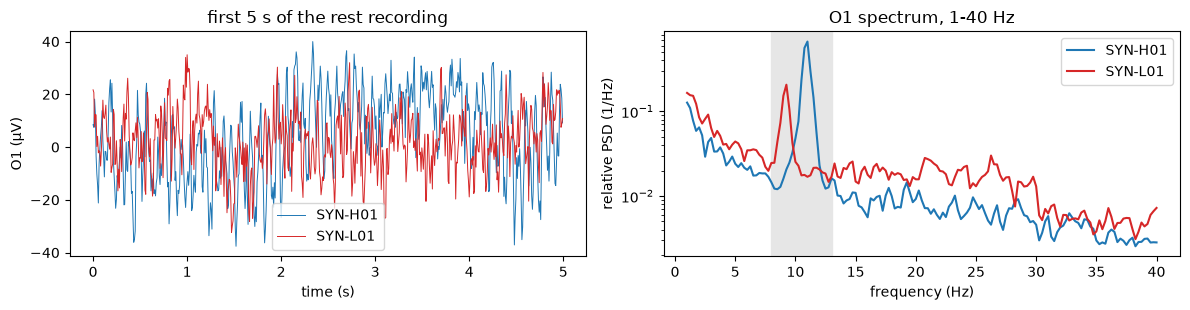

In [3]:
from ptsd_eeg.io import CHANNELS, load_edf_with_header, rest_path

fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
for sid, colour in [("SYN-H01", "C0"), ("SYN-L01", "C3")]:
    x, fs, header = load_edf_with_header(rest_path(demo_dir / sid))
    o1 = x[CHANNELS.index("O1")]
    t = np.arange(o1.size) / fs
    sel = t < 5
    axes[0].plot(t[sel], o1[sel], colour, lw=0.7, label=sid)
    from scipy.signal import welch
    f, p = welch(o1, fs=fs, nperseg=int(4 * fs))
    band = (f >= 1) & (f <= 40)
    axes[1].semilogy(f[band], p[band] / np.trapz(p[band], f[band]), colour, label=sid)
axes[0].set(xlabel="time (s)", ylabel="O1 (µV)", title="first 5 s of the rest recording")
axes[1].axvspan(8, 13, color="0.9")
axes[1].set(xlabel="frequency (Hz)", ylabel="relative PSD (1/Hz)", title="O1 spectrum, 1-40 Hz")
for a in axes: a.legend()
plt.tight_layout()
print(f"fs = {fs} Hz, {header.n_signals} signals, {header.actual_records} records of "
      f"{header.record_duration_s} s, labels {list(header.labels)}")

## 3. Set A features

Individual alpha frequency (IAF, Hz), occipital relative alpha (8-13 Hz), relative alpha in the individual band (IAF ± 2 Hz) and occipital relative beta (13-30 Hz), all from the rest file.

In [4]:
from ptsd_eeg.features import extract_subject

SET_A = ["rest_IAF", "rest_rel_alpha_O", "rest_rel_alpha_IAF", "rest_rel_beta_O"]
rows = []
for sid in ["SYN-H01", "SYN-H02", "SYN-L01", "SYN-L02"]:
    f = extract_subject(demo_dir / sid)
    rows.append({"subject": sid, **{k: f[k] for k in SET_A}, "epochs_kept": f"{f['n_kept']}/{f['n_epochs']}"})
pd.DataFrame(rows).set_index("subject")

,rest_IAF,rest_rel_alpha_O,rest_rel_alpha_IAF,rest_rel_beta_O,epochs_kept
subject,,,,,
SYN-H01,11.0,0.5938,0.5788,0.1395,59/59
SYN-H02,10.5,0.6369,0.6244,0.1293,59/59
SYN-L01,9.0,0.2456,0.2367,0.3506,59/59
SYN-L02,10.5,0.2464,0.2239,0.3355,59/59


## 4. Shipped weights

`weights/` holds the 90 × 100 LDA members as arrays in `c2g_members.npz`, the metadata in `model_meta.json` and checksums in `SHA256SUMS`. `load_weights` verifies the checksums and reads the arrays with `allow_pickle=False`.

In [5]:
from ptsd_eeg.weights import DEFAULT_WEIGHTS_DIR, load_weights, verify_weights

print(verify_weights(DEFAULT_WEIGHTS_DIR))
model = load_weights()
{k: model[k] for k in ["recipe", "feature_names", "threshold", "fallback_score", "n_train", "n_ptsd", "n_negative"]} | {"n_members": len(model["members"])}

{'c2g_members.npz': True, 'model_meta.json': True}


{'recipe': 'C2G',
 'feature_names': ['rest_IAF',
  'rest_rel_alpha_O',
  'rest_rel_alpha_IAF',
  'rest_rel_beta_O'],
 'threshold': 0.5,
 'fallback_score': 0.26666666666666666,
 'n_train': 90,
 'n_ptsd': 24,
 'n_negative': 66,
 'n_members': 90}

## 5. Scores

Each subject gets the mean probability of the 90 members. Subjects whose rest recording is unreadable, missing, flat or shorter than 30 s receive the prior `24/90 ≈ 0.267` (fallback) instead of a model score. The decision threshold is 0.5.

In [6]:
from ptsd_eeg.model import predict

scores = []
for sid in subjects.subject_id:
    try:
        p = predict(model, demo_dir / sid)
    except Exception as exc:
        p = float(model["fallback_score"])
    scores.append(p)
out = subjects.assign(score=scores)
out["fallback"] = np.isclose(out.score, model["fallback_score"])
out["above_threshold"] = out.score >= model["threshold"]
out

,subject_id,kind,edge,score,fallback,above_threshold
0,SYN-H01,high_alpha,,0.5391,False,True
1,SYN-H02,high_alpha,,0.6145,False,True
2,SYN-H03,high_alpha,,0.5896,False,True
3,SYN-H04,high_alpha,,0.6035,False,True
4,SYN-L01,low_alpha,,0.2188,False,False
5,SYN-L02,low_alpha,,0.1762,False,False
6,SYN-L03,low_alpha,,0.2065,False,False
7,SYN-L04,low_alpha,,0.1567,False,False
8,SYN-E01-short,high_alpha,short,0.2667,True,False
9,SYN-E02-truncated,high_alpha,truncated,0.2667,True,False


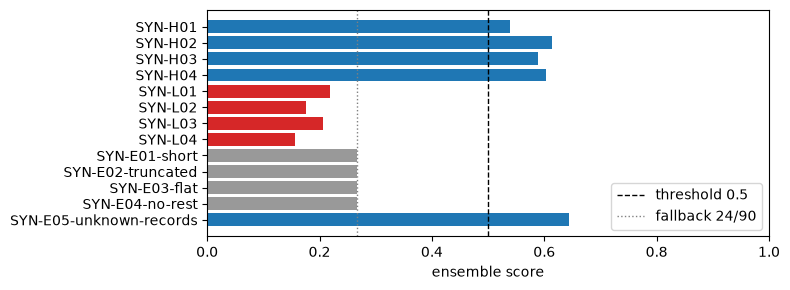

In [7]:
fig, ax = plt.subplots(figsize=(8, 3))
colours = out.kind.map({"high_alpha": "C0", "low_alpha": "C3"}).where(~out.fallback, "0.6")
ax.barh(out.subject_id, out.score, color=colours)
ax.axvline(model["threshold"], color="k", ls="--", lw=1, label="threshold 0.5")
ax.axvline(model["fallback_score"], color="0.5", ls=":", lw=1, label="fallback 24/90")
ax.invert_yaxis(); ax.set_xlim(0, 1); ax.set_xlabel("ensemble score"); ax.legend(loc="lower right")
plt.tight_layout()

The same result from the command line:

```bash
python examples/make_synthetic_edf.py demo .demo/edf
ptsd-eeg predict .demo/edf .demo/predictions.csv
```

## 6. Ensemble coefficients

Coefficients are on the robust-scaled, transformed features (`clr_*`: centred log-ratio of the occipital band powers; `logit_*`: logit of the individual-band alpha share). `share_positive` is the fraction of the 9000 member × bag fits with a positive coefficient; a positive coefficient raises the PTSD score.

In [8]:
from ptsd_eeg.weights import coefficient_table

coefficient_table(model)

,feature,mean,sd,p2_5,median,p97_5,share_positive,sd_across_members,mean_sd_across_bags,n_members,n_bags,p5,p95,member_mean_min,member_mean_max
0,rest_IAF,-0.3081,0.5075,-1.3328,-0.2917,0.7512,0.2433,0.0901,0.4997,90,100,-1.1485,0.4919,-0.5337,-0.0479
1,clr_alpha_O,1.5684,0.9193,0.2176,1.4016,3.7691,0.9866,0.4068,0.7884,90,100,0.3802,3.3283,0.7411,2.7694
2,logit_alpha_IAF,0.5474,0.5016,-0.2939,0.4931,1.6876,0.8904,0.0978,0.4903,90,100,-0.1652,1.4354,0.2476,0.7282
3,clr_beta_O,0.0456,0.7158,-1.2129,-0.0202,1.6047,0.4889,0.2524,0.6513,90,100,-0.9976,1.3282,-0.5164,0.7175


In [9]:
tmp.cleanup()